# Distribución de tokens y diagnóstico exploratorio de calidad

## Objetivo

Analizar la distribución de tokens de las respuestas ubicadas en las posiciones A y B, explorar la relación entre caracteres y tokens e identificar posibles situaciones de calidad de datos que puedan influir en el análisis de preferencias humanas.

## Alcance

El análisis se realizó sobre uno de los siete archivos Parquet que componen el dataset, correspondiente a 19.377 registros.

Las posiciones A y B representan las respuestas que se comparan en cada registro, por lo que no corresponden necesariamente a dos modelos fijos.

Los resultados obtenidos son exploratorios y no deben extrapolarse automáticamente a la totalidad del dataset.

In [1]:
from pathlib import Path
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from arena.io import RAW_DIR, REPO_ID

nombre_archivo = "data/train-00000-of-00007.parquet"
ruta = RAW_DIR / nombre_archivo

if not ruta.exists():
    ruta = Path(hf_hub_download(
        repo_id=REPO_ID,
        filename=nombre_archivo,
        repo_type="dataset",
        local_dir=RAW_DIR
    ))

print("¿Existe el archivo?", ruta.exists())

¿Existe el archivo? True


In [2]:
archivo = pq.ParquetFile(ruta)

print("Columnas del archivo:")
print(archivo.schema_arrow.names)

Columnas del archivo:
['id', 'model_a', 'model_b', 'winner', 'evaluation_session_id', 'evaluation_order', 'conversation_a', 'conversation_b', 'full_conversation', 'conv_metadata', 'category_tag', 'language', 'is_code', 'timestamp']


In [3]:
print(archivo.schema_arrow.field("conv_metadata").type)

struct<sum_assistant_a_tokens: int32, header_count_a: struct<h1: int64, h2: int64, h3: int64, h4: int64, h5: int64, h6: int64>, list_count_a: struct<ordered: int64, unordered: int64>, bold_count_a: struct<**: int64, __: int64>, context_a_tokens: int32, sum_assistant_b_tokens: int32, header_count_b: struct<h1: int64, h2: int64, h3: int64, h4: int64, h5: int64, h6: int64>, list_count_b: struct<ordered: int64, unordered: int64>, bold_count_b: struct<**: int64, __: int64>, context_b_tokens: int32, sum_user_tokens: int32, turns: int32>


In [4]:
metadata = archivo.schema_arrow.field("conv_metadata").type

for campo in metadata:
    print(campo.name)

sum_assistant_a_tokens
header_count_a
list_count_a
bold_count_a
context_a_tokens
sum_assistant_b_tokens
header_count_b
list_count_b
bold_count_b
context_b_tokens
sum_user_tokens
turns


In [5]:
tabla = archivo.read(columns=["conv_metadata"])

muestra = tabla.slice(0, 5)

for registro in muestra["conv_metadata"].to_pylist():
    print(
        "Modelo A:", registro["sum_assistant_a_tokens"],
        "| Modelo B:", registro["sum_assistant_b_tokens"]
    )

Modelo A: 1854 | Modelo B: 264
Modelo A: 605 | Modelo B: 407
Modelo A: 2216 | Modelo B: 2079
Modelo A: 297 | Modelo B: 931
Modelo A: 459 | Modelo B: 1284


In [6]:
tokens_a = []
tokens_b = []

for registro in tabla["conv_metadata"].to_pylist():
    tokens_a.append(registro["sum_assistant_a_tokens"])
    tokens_b.append(registro["sum_assistant_b_tokens"])

print("Registros del modelo A:", len(tokens_a))
print("Registros del modelo B:", len(tokens_b))

Registros del modelo A: 19377
Registros del modelo B: 19377


In [7]:
import numpy as np

tokens_a_log = np.log1p(tokens_a)

print("Primeros 5 valores originales:", tokens_a[:5])
print("Primeros 5 valores transformados:", tokens_a_log[:5])

Primeros 5 valores originales: [1854, 605, 2216, 297, 459]
Primeros 5 valores transformados: [7.52563998 6.40687999 7.70391021 5.69709349 6.13122649]


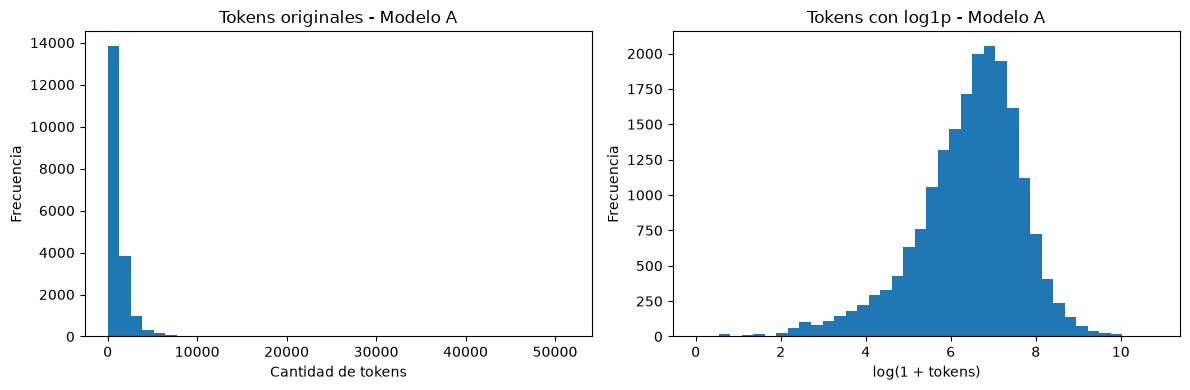

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(tokens_a, bins=40)
plt.title("Tokens originales - Modelo A")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
plt.hist(tokens_a_log, bins=40)
plt.title("Tokens con log1p - Modelo A")
plt.xlabel("log(1 + tokens)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [9]:
tokens_b_log = np.log1p(tokens_b)

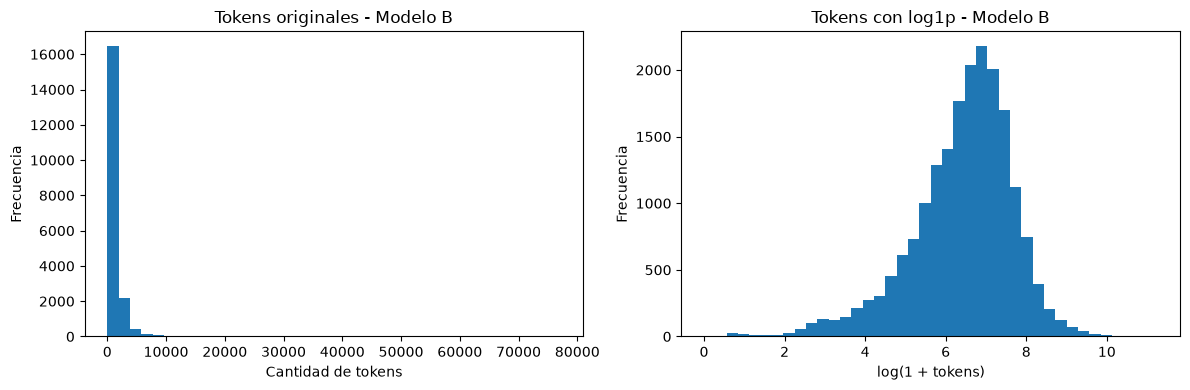

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(tokens_b, bins=40)
plt.title("Tokens originales - Modelo B")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
plt.hist(tokens_b_log, bins=40)
plt.title("Tokens con log1p - Modelo B")
plt.xlabel("log(1 + tokens)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [11]:
print("MODELO A")
print("Promedio:", np.mean(tokens_a))
print("Mediana:", np.median(tokens_a))
print("Máximo:", np.max(tokens_a))

print("MODELO B")
print("Promedio:", np.mean(tokens_b))
print("Mediana:", np.median(tokens_b))
print("Máximo:", np.max(tokens_b))

MODELO A
Promedio: 1149.1172008050783
Mediana: 744.0
Máximo: 51560
MODELO B
Promedio: 1137.0624967745266
Mediana: 742.0
Máximo: 77151


In [12]:
print(archivo.schema_arrow.field("conversation_a").type)

list<element: struct<role: string, content: list<element: struct<type: string, text: string, image: string, mimeType: string>>>>


In [13]:
lote = next(archivo.iter_batches(
    batch_size=1,
    columns=["conversation_a"]
))

conversacion = lote.column("conversation_a")[0].as_py()

for mensaje in conversacion:
    print("Rol:", mensaje["role"])
    print("Tipo de contenido:", [
        parte["type"] for parte in mensaje["content"]
    ])

Rol: user
Tipo de contenido: ['text']
Rol: assistant
Tipo de contenido: ['text']


In [14]:
caracteres_a = 0

for mensaje in conversacion:
    if mensaje["role"] == "assistant":
        for parte in mensaje["content"]:
            if parte["type"] == "text" and parte["text"] is not None:
                caracteres_a += len(parte["text"])

print("Caracteres del modelo A:", caracteres_a)
print("Tokens del modelo A:", tokens_a[0])

Caracteres del modelo A: 7542
Tokens del modelo A: 1854


In [15]:
lote_b = next(archivo.iter_batches(
    batch_size=1,
    columns=["conversation_b"]
))

conversacion_b = lote_b.column("conversation_b")[0].as_py()

caracteres_b = 0

for mensaje in conversacion_b:
    if mensaje["role"] == "assistant":
        for parte in mensaje["content"]:
            if parte["type"] == "text" and parte["text"] is not None:
                caracteres_b += len(parte["text"])

print("Caracteres del modelo B:", caracteres_b)
print("Tokens del modelo B:", tokens_b[0])

Caracteres del modelo B: 1120
Tokens del modelo B: 264


In [16]:
relacion_a = caracteres_a / tokens_a[0]
relacion_b = caracteres_b / tokens_b[0]

print("Modelo A:", round(relacion_a, 2))
print("Modelo B:", round(relacion_b, 2))

Modelo A: 4.07
Modelo B: 4.24


In [17]:
from collections import Counter

idiomas = archivo.read(columns=["language"]).column("language").to_pylist()

conteo_idiomas = Counter(idiomas)

print(conteo_idiomas.most_common(10))

[('en', 10226), ('pl', 1940), ('und', 1727), ('ru', 1338), ('zh', 924), ('de', 625), ('ja', 353), ('ko', 341), ('fr', 289), ('pt', 226)]


In [18]:
tokens_a_ingles = []
tokens_b_ingles = []

for posicion, idioma in enumerate(idiomas):
    if idioma == "en":
        tokens_a_ingles.append(tokens_a[posicion])
        tokens_b_ingles.append(tokens_b[posicion])

print("Registros A en inglés:", len(tokens_a_ingles))
print("Registros B en inglés:", len(tokens_b_ingles))

Registros A en inglés: 10226
Registros B en inglés: 10226


In [19]:
def contar_caracteres(conversacion):
    total = 0

    for mensaje in conversacion:
        if mensaje["role"] == "assistant":
            for parte in mensaje["content"]:
                if parte["type"] == "text" and parte["text"] is not None:
                    total += len(parte["text"])

    return total

print("Modelo A:", contar_caracteres(conversacion))
print("Modelo B:", contar_caracteres(conversacion_b))

Modelo A: 7542
Modelo B: 1120


In [20]:
caracteres_a_ingles = []
caracteres_b_ingles = []

for lote in archivo.iter_batches(
    batch_size=200,
    columns=["language", "conversation_a", "conversation_b"]
):
    for registro in lote.to_pylist():
        if registro["language"] == "en":
            caracteres_a_ingles.append(
                contar_caracteres(registro["conversation_a"])
            )
            caracteres_b_ingles.append(
                contar_caracteres(registro["conversation_b"])
            )

print("Respuestas A analizadas:", len(caracteres_a_ingles))
print("Respuestas B analizadas:", len(caracteres_b_ingles))

Respuestas A analizadas: 10226
Respuestas B analizadas: 10226


In [21]:
relaciones_a = []
relaciones_b = []

for ca, cb, ta, tb in zip(
    caracteres_a_ingles,
    caracteres_b_ingles,
    tokens_a_ingles,
    tokens_b_ingles
):
    if ta > 0 and tb > 0 and ca > 0 and cb > 0:
        relaciones_a.append(ca / ta)
        relaciones_b.append(cb / tb)

print("Conversaciones comparables:", len(relaciones_a))
print("Mediana modelo A:", round(np.median(relaciones_a), 2))
print("Mediana modelo B:", round(np.median(relaciones_b), 2))

Conversaciones comparables: 10221
Mediana modelo A: 4.35
Mediana modelo B: 4.34


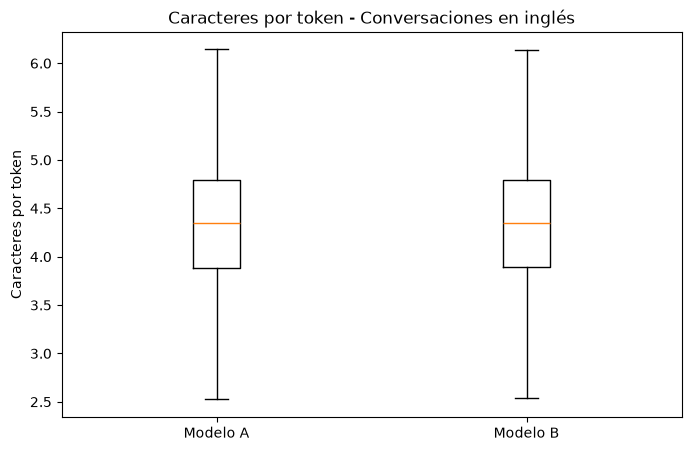

In [22]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [relaciones_a, relaciones_b],
    tick_labels=["Modelo A", "Modelo B"],
    showfliers=False
)

plt.title("Caracteres por token - Conversaciones en inglés")
plt.ylabel("Caracteres por token")

plt.show()

## Validación exploratoria de caracteres por token

Se realizó una comparación entre la cantidad de caracteres y tokens registrados para las respuestas de los modelos ubicados en las posiciones A y B de cada comparación, con el objetivo de evaluar si estas medidas de extensión presentan un comportamiento similar.

Para este análisis, se seleccionaron las conversaciones clasificadas como inglés. De un total de 10.226 conversaciones, se utilizaron 10.221 que contaban con valores positivos de caracteres y tokens en ambas respuestas.

Los resultados mostraron una mediana de 4,35 caracteres por token para el modelo A y 4,34 para el modelo B. Además, los diagramas de caja muestran una dispersión central bastante similar.

Si bien estos resultados sugieren un comportamiento parecido en las medidas analizadas, no permiten confirmar que ambos modelos utilicen el mismo tokenizador. Para ello sería necesario verificar la metodología utilizada para obtener los conteos originales.

Cabe señalar que este análisis es exploratorio y se realizó sobre uno de los siete archivos que componen el dataset.

In [23]:
ceros_a = sum(token == 0 for token in tokens_a)
ceros_b = sum(token == 0 for token in tokens_b)

print("Respuestas A con 0 tokens:", ceros_a)
print("Respuestas B con 0 tokens:", ceros_b)

Respuestas A con 0 tokens: 5
Respuestas B con 0 tokens: 4


In [24]:
ambos_cero = sum(
    a == 0 and b == 0
    for a, b in zip(tokens_a, tokens_b)
)

algun_cero = sum(
    a == 0 or b == 0
    for a, b in zip(tokens_a, tokens_b)
)

print("Conversaciones con ambos valores en cero:", ambos_cero)
print("Conversaciones con al menos un cero:", algun_cero)

Conversaciones con ambos valores en cero: 0
Conversaciones con al menos un cero: 9


In [25]:
indices_cero = []

for posicion, (a, b) in enumerate(zip(tokens_a, tokens_b)):
    if a == 0 or b == 0:
        indices_cero.append(posicion)

print("Posiciones encontradas:", indices_cero)
print("Total de conversaciones:", len(indices_cero))

Posiciones encontradas: [4067, 4093, 4665, 4790, 12843, 13231, 14958, 16089, 16562]
Total de conversaciones: 9


In [26]:
posicion = 0

for lote in archivo.iter_batches(
    batch_size=200,
    columns=["conversation_a", "conversation_b"]
):
    for registro in lote.to_pylist():
        if posicion in indices_cero:
            print("Registro:", posicion)
            print("Tokens A:", tokens_a[posicion])
            print("Caracteres A:", contar_caracteres(registro["conversation_a"]))
            print("Tokens B:", tokens_b[posicion])
            print("Caracteres B:", contar_caracteres(registro["conversation_b"]))
            print("---------------------")

        posicion += 1

Registro: 4067
Tokens A: 0
Caracteres A: 0
Tokens B: 1153
Caracteres B: 1093
---------------------
Registro: 4093
Tokens A: 0
Caracteres A: 0
Tokens B: 488
Caracteres B: 2385
---------------------
Registro: 4665
Tokens A: 0
Caracteres A: 0
Tokens B: 6
Caracteres B: 27
---------------------
Registro: 4790
Tokens A: 484
Caracteres A: 1717
Tokens B: 0
Caracteres B: 0
---------------------
Registro: 12843
Tokens A: 0
Caracteres A: 0
Tokens B: 597
Caracteres B: 2473
---------------------
Registro: 13231
Tokens A: 240
Caracteres A: 968
Tokens B: 0
Caracteres B: 0
---------------------
Registro: 14958
Tokens A: 1146
Caracteres A: 4403
Tokens B: 0
Caracteres B: 0
---------------------
Registro: 16089
Tokens A: 601
Caracteres A: 2020
Tokens B: 0
Caracteres B: 0
---------------------
Registro: 16562
Tokens A: 0
Caracteres A: 0
Tokens B: 65
Caracteres B: 166
---------------------


In [27]:
ganadores = archivo.read(
    columns=["winner"]
).column("winner").to_pylist()

for posicion in indices_cero:
    lado_sin_texto = "A" if tokens_a[posicion] == 0 else "B"

    print(
        f"Registro {posicion}: "
        f"Sin texto en {lado_sin_texto} | "
        f"Ganador: {ganadores[posicion]}"
    )

Registro 4067: Sin texto en A | Ganador: both_bad
Registro 4093: Sin texto en A | Ganador: model_b
Registro 4665: Sin texto en A | Ganador: model_a
Registro 4790: Sin texto en B | Ganador: both_bad
Registro 12843: Sin texto en A | Ganador: model_b
Registro 13231: Sin texto en B | Ganador: model_a
Registro 14958: Sin texto en B | Ganador: both_bad
Registro 16089: Sin texto en B | Ganador: model_a
Registro 16562: Sin texto en A | Ganador: model_a


In [28]:
objetivo = 4665
posicion = 0

for lote in archivo.iter_batches(
    batch_size=200,
    columns=["conversation_a"]
):
    if posicion <= objetivo < posicion + lote.num_rows:
        conversacion_caso = lote.column("conversation_a")[
            objetivo - posicion
        ].as_py()
        break

    posicion += lote.num_rows

In [29]:
for mensaje in conversacion_caso:
    if mensaje["role"] == "assistant":
        print("Contenido:", mensaje["content"])
        print("Cantidad de elementos:", len(mensaje["content"]))

print("Ganador registrado:", ganadores[4665])

Contenido: []
Cantidad de elementos: 0
Ganador registrado: model_a


In [30]:
from collections import Counter

resultados = Counter(ganadores)

for resultado, cantidad in resultados.items():
    print(resultado, ":", cantidad)

model_a : 6952
tie : 3129
both_bad : 2164
model_b : 7132


In [31]:
modelos = archivo.read(
    columns=["model_a", "model_b"]
).to_pylist()

mismo_modelo = 0

for registro in modelos:
    if registro["model_a"] == registro["model_b"]:
        mismo_modelo += 1

print("Comparaciones con el mismo modelo:", mismo_modelo)

Comparaciones con el mismo modelo: 1


In [32]:
for posicion, registro in enumerate(modelos):
    if registro["model_a"] == registro["model_b"]:
        print("Registro:", posicion)
        print("Modelo A:", registro["model_a"])
        print("Modelo B:", registro["model_b"])
        print("Ganador:", ganadores[posicion])
        print("Tokens A:", tokens_a[posicion])
        print("Tokens B:", tokens_b[posicion])

Registro: 4878
Modelo A: gemini-2.5-flash-preview-04-17
Modelo B: gemini-2.5-flash-preview-04-17
Ganador: tie
Tokens A: 662
Tokens B: 690


In [33]:
indices_und = []

for posicion, idioma in enumerate(idiomas):
    if idioma == "und":
        indices_und.append(posicion)

resultados_und = Counter(
    ganadores[posicion] for posicion in indices_und
)

print("Conversaciones con idioma no determinado:", len(indices_und))
print("Resultados de evaluación:", resultados_und)

Conversaciones con idioma no determinado: 1727
Resultados de evaluación: Counter({'model_a': 660, 'model_b': 590, 'tie': 290, 'both_bad': 187})


## Diagnóstico de calidad de datos y decisiones metodológicas

A partir de la revisión de uno de los siete archivos que componen el dataset, se identificaron distintas situaciones que podrían influir en el análisis de preferencias humanas. Para cada una se propone una decisión metodológica, buscando conservar la información original y evitar introducir sesgos antes de realizar el análisis estadístico.

| Problema de calidad | Cifra identificada | Decisión propuesta | Justificación |
|---|---|---|---|
| Tokens en cero | 9 de 19.377 registros | Conservar los registros originales y marcarlos para revisión. Evaluar su exclusión del análisis principal de extensión. | Se identificaron respuestas con cero tokens y cero caracteres. En dos casos, la posición sin texto figura como ganadora, lo que podría afectar la interpretación de los resultados. |
| Empates (`tie`) | 3.129 de 19.377 registros | Conservar los registros e identificarlos por separado. No considerarlos como victorias de A o B. | Al existir un empate, no es posible determinar cuál respuesta fue preferida, aunque una tenga mayor extensión que la otra. |
| Ambas respuestas malas (`both_bad`) | 2.164 de 19.377 registros | Conservar los registros y analizar esta categoría por separado. | Ambas respuestas fueron calificadas como malas, por lo que no corresponde asignar una victoria individual a ninguno de los modelos. |
| Mismo modelo en A y B | 1 de 19.377 registros | Conservar e identificar por separado para evaluar su uso según el análisis. | Ambas respuestas provienen del mismo modelo, por lo que no permiten comparar preferencias entre modelos diferentes. Sin embargo, pueden aportar información sobre la relación entre la extensión de las respuestas y la evaluación humana. |
| Idioma no determinado (`und`) | 1.727 de 19.377 registros (8,9 %) | Conservar los registros originales e identificarlos por separado. No incluirlos en los análisis específicos del idioma inglés. | Al no conocer el idioma, no es posible asegurar que las diferencias en caracteres y tokens sean comparables bajo las mismas condiciones. Sin embargo, estos registros pueden aportar información en otros análisis de preferencias humanas. |
| Asimetría en la cantidad de tokens | Medianas: A = 744 y B = 742. Máximos: A = 51.560 y B = 77.151. | Conservar los valores originales y utilizar la transformación `log1p` para facilitar la visualización de las distribuciones. | Se observó una concentración de respuestas con menos tokens y algunos valores extremadamente altos. La transformación logarítmica reduce el efecto visual de estos extremos, permitiendo apreciar mejor la distribución sin modificar los datos originales. |

### Conclusión del diagnóstico

A partir del análisis realizado, se identificaron distintas situaciones que podrían influir en los resultados de nuestra investigación, como respuestas con cero tokens, empates, idiomas no determinados y diferencias importantes en la extensión de las respuestas.

Por este motivo, se propone conservar todos los registros en los datos originales e identificar aquellos que requieren un tratamiento especial, dependiendo del análisis que se realice. Esto permitirá trabajar con criterios definidos y evitar que las decisiones de limpieza introduzcan sesgos antes de evaluar nuestra pregunta de investigación.

También se comprobó que la distribución de tokens presenta una asimetría hacia la derecha. Por ello, se utilizó la transformación `log1p` para facilitar su visualización, manteniendo disponibles los valores originales.

Cabe señalar que estos resultados corresponden únicamente a uno de los siete archivos del dataset, por lo que todavía no pueden considerarse representativos de la totalidad de los datos.